<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,Income,Age,Loan_Amount,Payment_History,Credit_Utilization,Credit_Score
0,136958,22,6015,6,21,Good
1,146932,52,66813,8,62,Good
2,118694,43,32712,9,80,Good
3,134879,42,13415,5,19,Good
4,125268,45,67292,3,54,Average
5,69886,42,28833,5,26,Average
6,102498,42,9158,5,35,Good
7,127727,62,67680,5,94,Average
8,141324,26,25309,3,71,Average
9,31023,35,11970,10,55,Average



Total Samples: 300

Input Features:
['Income', 'Age', 'Loan_Amount', 'Payment_History', 'Credit_Utilization']

Training Samples: 240
Testing Samples: 60

========== MODEL TRAINING COMPLETED ==========
Algorithm: Random Forest Classifier

========== PREDICTION RESULTS ==========


,Actual Credit Score,Predicted Credit Score
0,Good,Average
1,Average,Average
2,Average,Average
3,Average,Average
4,Average,Poor
5,Average,Average
6,Good,Good
7,Average,Good
8,Poor,Average
9,Average,Average


Testing Accuracy: 81.67 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     Average       0.72      0.82      0.77        22
        Good       0.85      0.79      0.81        14
        Poor       0.91      0.83      0.87        24

    accuracy                           0.82        60
   macro avg       0.83      0.81      0.82        60
weighted avg       0.83      0.82      0.82        60



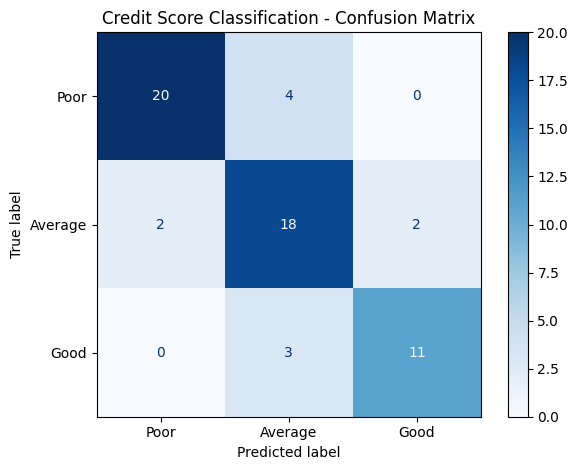

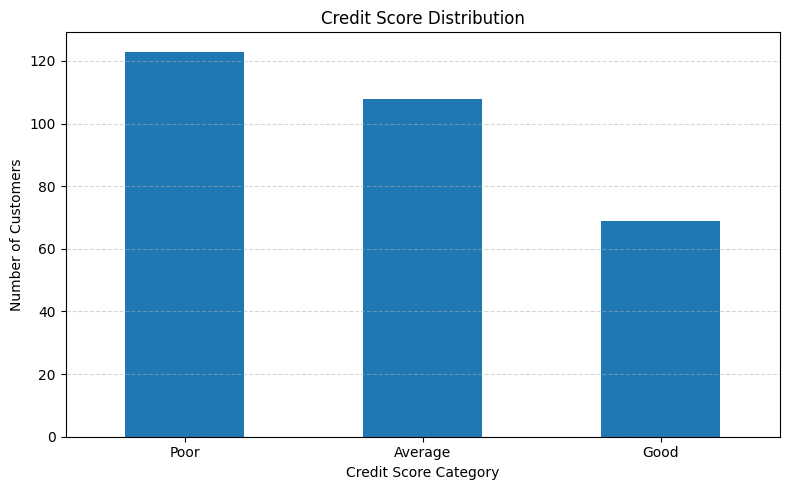

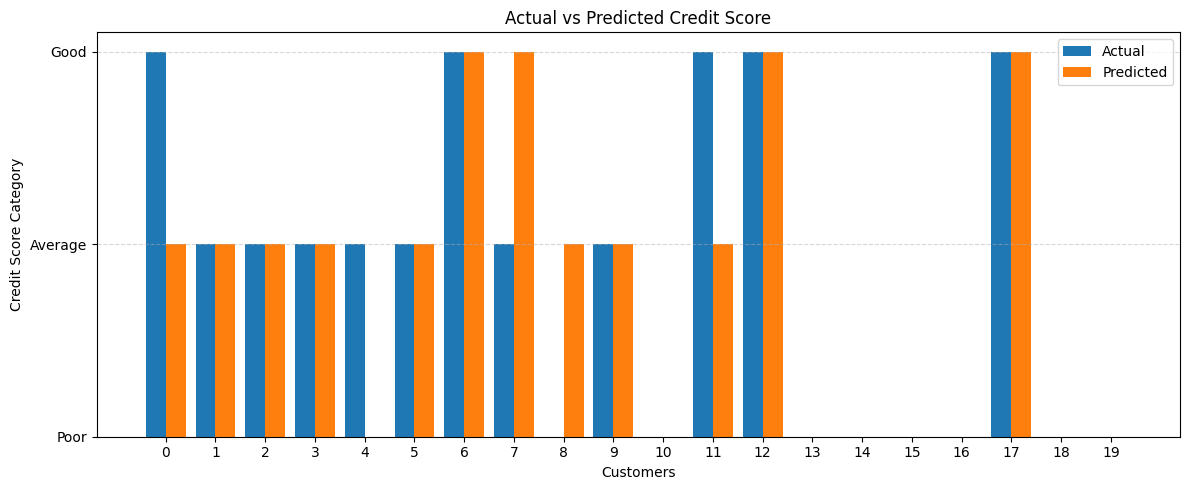

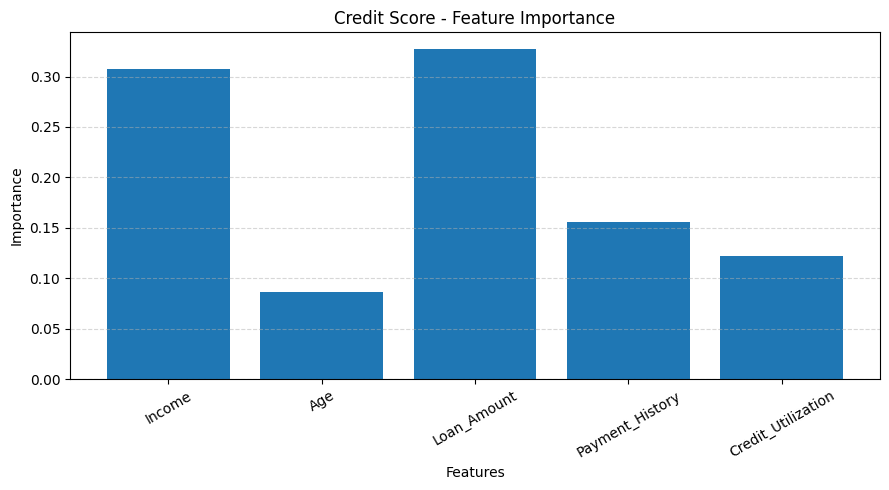


========== NEW CUSTOMER PREDICTION ==========


,Income,Age,Loan_Amount,Payment_History,Credit_Utilization
0,75000,30,20000,9,25


Predicted Credit Score: Good

========== FINAL RESULT ==========
Credit Score Classification Completed Successfully.
Testing Accuracy: 81.67 %
Algorithm: Random Forest Classifier


In [1]:
# EXPERIMENT 11: CREDIT SCORE CLASSIFICATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# STEP 1: CREATE TRAINING DATASET

np.random.seed(42)

n = 300

data = {
    'Income': np.random.randint(15000, 150000, n),
    'Age': np.random.randint(21, 65, n),
    'Loan_Amount': np.random.randint(5000, 100000, n),
    'Payment_History': np.random.randint(1, 11, n),
    'Credit_Utilization': np.random.randint(10, 100, n)
}

df = pd.DataFrame(data)

# Generate credit score categories
score = (
    0.30 * (df['Income'] / 1000)
    + 3 * df['Payment_History']
    - 0.04 * df['Loan_Amount'] / 100
    - 0.15 * df['Credit_Utilization']
    + 0.1 * df['Age']
)

df['Credit_Score'] = pd.cut(
    score,
    bins=[-np.inf, 15, 35, np.inf],
    labels=['Poor', 'Average', 'Good']
)

print("========== TRAINING DATASET ==========")
display(df.head(15))

print("\nTotal Samples:", len(df))

# STEP 2: SPLIT FEATURES AND TARGET

X = df.drop('Credit_Score', axis=1)
y = df['Credit_Score']

print("\nInput Features:")
print(list(X.columns))

# STEP 3: SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 4: FEATURE SCALING

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# STEP 5: CREATE CLASSIFICATION MODEL

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# STEP 6: TRAIN THE MODEL

model.fit(X_train_scaled, y_train)

print("\n========== MODEL TRAINING COMPLETED ==========")
print("Algorithm: Random Forest Classifier")

# STEP 7: PREDICT CREDIT SCORE

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== PREDICTION RESULTS ==========")

results = pd.DataFrame({
    'Actual Credit Score': y_test.values,
    'Predicted Credit Score': y_pred
})

display(results.head(20))

print("Testing Accuracy:", round(accuracy * 100, 2), "%")

# STEP 8: CLASSIFICATION REPORT

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(y_test, y_pred))

# STEP 9: CONFUSION MATRIX

labels = ['Poor', 'Average', 'Good']

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Credit Score Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 10: CREDIT SCORE DISTRIBUTION

plt.figure(figsize=(8, 5))

df['Credit_Score'].value_counts().reindex(
    labels, fill_value=0
).plot(kind='bar')

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# STEP 11: ACTUAL VS PREDICTED GRAPH

sample_count = min(20, len(y_test))
index = np.arange(sample_count)

actual = pd.Categorical(
    y_test.iloc[:sample_count],
    categories=labels
).codes

predicted = pd.Categorical(
    y_pred[:sample_count],
    categories=labels
).codes

plt.figure(figsize=(12, 5))

plt.bar(
    index - 0.2,
    actual,
    width=0.4,
    label='Actual'
)

plt.bar(
    index + 0.2,
    predicted,
    width=0.4,
    label='Predicted'
)

plt.title("Actual vs Predicted Credit Score")
plt.xlabel("Customers")
plt.ylabel("Credit Score Category")
plt.yticks([0, 1, 2], labels)
plt.xticks(index)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 12: FEATURE IMPORTANCE GRAPH

plt.figure(figsize=(9, 5))

plt.bar(
    X.columns,
    model.feature_importances_
)

plt.title("Credit Score - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# STEP 13: TEST A NEW CUSTOMER

new_customer = pd.DataFrame({
    'Income': [75000],
    'Age': [30],
    'Loan_Amount': [20000],
    'Payment_History': [9],
    'Credit_Utilization': [25]
})

new_customer_scaled = scaler.transform(new_customer)

prediction = model.predict(new_customer_scaled)

print("\n========== NEW CUSTOMER PREDICTION ==========")

display(new_customer)

print("Predicted Credit Score:", prediction[0])

# STEP 14: FINAL RESULT

print("\n========== FINAL RESULT ==========")

print("Credit Score Classification Completed Successfully.")

print("Testing Accuracy:", round(accuracy * 100, 2), "%")

print("Algorithm: Random Forest Classifier")